# Follow-Target Test Set Rollout

Evaluate a follow-target policy on **test set trajectories** from the HDF5
dataset. During training with `target_mode="dataset"`, the dataset is split
80/20 into train/test using a seeded permutation. This notebook reconstructs
that split and runs rollouts on the held-out test trajectories, using the
exact same initialization (qpos from HDF5) as training.

Unlike the moving-target notebook, no live imitation rollout is needed —
skull trajectories and initial poses come directly from the pre-computed
dataset.

In [26]:
%load_ext autoreload
%autoreload 2

import functools
import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

from pathlib import Path

import h5py
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import mujoco
import numpy as np
import mediapy as media
import orbax.checkpoint as ocp
import plotly.graph_objects as go
from matplotlib.backends.backend_agg import FigureCanvasAgg
from ml_collections import ConfigDict
from mujoco import mjx
from omegaconf import OmegaConf
from sklearn.decomposition import PCA

from brax.training.agents.ppo import networks as ppo_networks
from brax.training.acme import running_statistics, specs

from scamper.agent import checkpointing
from scamper.agent.task_transfer.follow_target.checkpoint_utils import (
    load_task_transfer_metadata,
    _create_abstract_prior_policy,
    _STEP_PREFIX,
    make_decoder_inference_fn,
    make_prior_inference_fn,
    load_task_transfer_brax_params,
)
from scamper.agent.task_transfer.follow_target.train import (
    extract_skull_trajectories,
)
from scamper.agent.task_transfer.follow_target.wrappers import (
    DecoderHighLevelWrapper,
    PriorDecoderHighLevelWrapper,
    _flatten_obs_for_policy,
)
from vnl_playground.tasks.rodent import consts as rodent_consts
from vnl_playground.tasks.rodent import follow_target

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Configuration

In [143]:
# ============ CHECKPOINT ============
# Path to the follow_target task transfer checkpoint directory
FOLLOW_TARGET_CHECKPOINT_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/scratch/follow_target_checkpoints/260213_115512_573813"

# Checkpoint step to load (None = latest)
CHECKPOINT_STEP = 47

# Path prefix replacement for checkpoints saved on a different machine.
# Set both to None to skip path fixing.
OLD_PATH_PREFIX = "/tmp/track-mjx"  # e.g., "/tmp/scamper"
NEW_PATH_PREFIX = "/home/mila/a/aidan.sirbu/SCAMPER"  # e.g., "/home/user/scamper"

# ============ ENVIRONMENT OVERRIDES ============
# MuJoCo backend: "jax" or "warp" (None = use checkpoint default)
MUJOCO_IMPL = "warp"

# Walker XML variant (None = use checkpoint default)
# Options: "rodent.xml", "rodent_full_collisions.xml",
#          "rodent_no_tail_collisions.xml", "rodent_box_feet.xml"
WALKER_XML = "rodent_no_tail_collisions.xml"

# ============ ROLLOUT SETTINGS ============
DETERMINISTIC = True  # Use mean action (no sampling)

# ============ RENDERING ============
RENDER_HEIGHT = 480
RENDER_WIDTH = 640
RENDER_FPS = 50
CAMERA_NAME = "close_profile-rodent"

## Load Frozen Networks from Task Transfer Checkpoint

In [144]:
# 1. Load metadata (JSON only, lightweight)
metadata = load_task_transfer_metadata(FOLLOW_TARGET_CHECKPOINT_PATH, CHECKPOINT_STEP)
config = metadata["config"]
step = metadata["step"]
ckpt_cfg = config["checkpoint_config"]
ckpt_cfg_omega = OmegaConf.create(ckpt_cfg)

print(f"Loaded metadata from step {step}")
print(f"Training mode: {config.get('mode', 'unknown')}")
print(f"Latent size: {ckpt_cfg['network_config']['intention_size']}")
print(f"Action size: {ckpt_cfg['network_config']['action_size']}")

# 2. Fix paths if needed
OmegaConf.set_struct(ckpt_cfg_omega, False)

if OLD_PATH_PREFIX is not None and NEW_PATH_PREFIX is not None:

    def fix_path(p):
        if p and p.startswith(OLD_PATH_PREFIX):
            return p.replace(OLD_PATH_PREFIX, NEW_PATH_PREFIX, 1)
        return p

    for key in ["walker_xml_path", "arena_xml_path", "reference_data_path"]:
        OmegaConf.update(
            ckpt_cfg_omega,
            f"env_config.{key}",
            fix_path(ckpt_cfg_omega.env_config[key]),
        )

# Auto-fix XML paths if they don't exist on disk
_xml_lookup = {
    "rodent_full_collisions.xml": str(rodent_consts.RODENT_FULL_COLLISION_XML),
    "rodent_no_tail_collisions.xml": str(rodent_consts.RODENT_NO_TAIL_COLLISION_XML),
    "rodent_box_feet.xml": str(rodent_consts.RODENT_BOX_FEET_PATH),
    "rodent.xml": str(rodent_consts.RODENT_XML_PATH),
    "arena.xml": str(rodent_consts.ARENA_XML_PATH),
}

for key in ["walker_xml_path", "arena_xml_path"]:
    current = ckpt_cfg_omega.env_config[key]
    if not Path(current).exists():
        filename = Path(current).name
        fallback = _xml_lookup.get(filename)
        if fallback is not None:
            OmegaConf.update(ckpt_cfg_omega, f"env_config.{key}", fallback)
            print(f"Fixed {key}: {filename} -> {fallback}")
        else:
            print(f"Warning: {key} not found and no fallback for '{filename}'")

# 3. Apply environment overrides from Configuration cell
if MUJOCO_IMPL is not None:
    OmegaConf.update(ckpt_cfg_omega, "env_config.mujoco_impl", MUJOCO_IMPL)

if WALKER_XML is not None:
    resolved = _xml_lookup.get(WALKER_XML)
    if resolved is not None:
        OmegaConf.update(ckpt_cfg_omega, "env_config.walker_xml_path", resolved)
    else:
        OmegaConf.update(ckpt_cfg_omega, "env_config.walker_xml_path", WALKER_XML)

print(f"\nPaths:")
print(f"  walker_xml: {ckpt_cfg_omega.env_config.walker_xml_path}")
print(f"  arena_xml: {ckpt_cfg_omega.env_config.arena_xml_path}")
print(f"  reference_data: {ckpt_cfg_omega.env_config.reference_data_path}")
print(f"  mujoco_impl: {ckpt_cfg_omega.env_config.mujoco_impl}")

# 4. Create abstract pytree structure for restoring frozen networks
abstract_policy = _create_abstract_prior_policy(ckpt_cfg_omega)
normalizer_state, combined_params = abstract_policy

abstract_frozen_networks = {
    "encoder_params": combined_params["params"]["encoder"],
    "prior_params": combined_params["params"]["prior"],
    "decoder_params": combined_params["params"]["decoder"],
    "imitation_normalizer": normalizer_state,
}

# 5. Restore frozen networks from task transfer checkpoint
mgr_options = ocp.CheckpointManagerOptions(create=False, step_prefix=_STEP_PREFIX)
with ocp.CheckpointManager(FOLLOW_TARGET_CHECKPOINT_PATH, options=mgr_options) as mgr:
    restored = mgr.restore(
        step,
        args=ocp.args.Composite(
            frozen_networks=ocp.args.StandardRestore(abstract_frozen_networks),
        ),
    )

frozen = restored["frozen_networks"]
encoder_params = frozen["encoder_params"]
decoder_params = frozen["decoder_params"]
imitation_normalizer = frozen["imitation_normalizer"]

encoder_count = sum(p.size for p in jax.tree_util.tree_leaves(encoder_params))
decoder_count = sum(p.size for p in jax.tree_util.tree_leaves(decoder_params))
print(f"\nFrozen networks loaded successfully")
print(f"  Encoder parameters: {encoder_count:,}")
print(f"  Decoder parameters: {decoder_count:,}")

Loaded metadata from step 47
Training mode: decoder_only
Latent size: 16
Action size: 38
Fixed walker_xml_path: rodent.xml -> /home/mila/a/aidan.sirbu/vnl-playground/vnl_playground/tasks/rodent/xmls/rodent.xml
Fixed arena_xml_path: arena.xml -> /home/mila/a/aidan.sirbu/vnl-playground/vnl_playground/tasks/rodent/xmls/arena.xml

Paths:
  walker_xml: /home/mila/a/aidan.sirbu/vnl-playground/vnl_playground/tasks/rodent/xmls/rodent_no_tail_collisions.xml
  arena_xml: /home/mila/a/aidan.sirbu/vnl-playground/vnl_playground/tasks/rodent/xmls/arena.xml
  reference_data: /home/mila/a/aidan.sirbu/SCAMPER/data/rodent/rodent_reference_clips.h5
  mujoco_impl: warp

Frozen networks loaded successfully
  Encoder parameters: 4,501,536
  Decoder parameters: 1,919,564


## Load Dataset & Reconstruct Test Split

Read the HDF5 dataset referenced by the checkpoint config, extract skull
trajectories via forward kinematics, and reconstruct the train/test split
using the same seed and ratio from training.

In [145]:
# Read dataset config from checkpoint
dataset_path = config["env"]["dataset_path"]
dataset_key = config["env"].get("dataset_key", "encoder_decoder")
train_subset_ratio = config["env"].get("train_subset_ratio", 0.8)
seed = config["train"]["seed"]

# Fix dataset_path prefix if needed
if OLD_PATH_PREFIX is not None and NEW_PATH_PREFIX is not None:
    dataset_path = fix_path(dataset_path)

print(f"Dataset path: {dataset_path}")
print(f"Dataset key: {dataset_key}")
print(f"Train subset ratio: {train_subset_ratio}")
print(f"Seed: {seed}")

# Create temporary FollowTarget env for MuJoCo model (needed for FK)
ft_env_cfg = follow_target.default_config()
ckpt_cfg_dict = OmegaConf.to_container(ckpt_cfg_omega, resolve=True)
ft_env_cfg.ctrl_dt = ckpt_cfg_dict["env_config"]["ctrl_dt"]
if MUJOCO_IMPL is not None:
    ft_env_cfg.mujoco_impl = MUJOCO_IMPL
if WALKER_XML is not None:
    _ft_xml_lookup = {
        "rodent_full_collisions.xml": rodent_consts.RODENT_FULL_COLLISION_XML,
        "rodent_no_tail_collisions.xml": rodent_consts.RODENT_NO_TAIL_COLLISION_XML,
        "rodent_box_feet.xml": rodent_consts.RODENT_BOX_FEET_PATH,
        "rodent.xml": rodent_consts.RODENT_XML_PATH,
    }
    ft_env_cfg.walker_xml_path = _ft_xml_lookup.get(WALKER_XML, WALKER_XML)

_fk_env = follow_target.FollowTarget(config=ft_env_cfg)
mj_model = _fk_env.mj_model

# Extract skull trajectories via FK
print(f"\nExtracting skull trajectories (this may take a minute)...")
skull_trajs, all_qpos = extract_skull_trajectories(dataset_path, dataset_key, mj_model)

num_trajs, traj_len, _ = skull_trajs.shape
print(f"Loaded {num_trajs} trajectories of length {traj_len}")
print(f"  skull_trajs shape: {skull_trajs.shape}")
print(f"  all_qpos shape: {all_qpos.shape}")

# Reconstruct train/test split (same logic as train.py)
num_train = max(1, int(num_trajs * train_subset_ratio))
num_test = num_trajs - num_train

perm = jax.random.permutation(jax.random.PRNGKey(seed), num_trajs)
train_idx = perm[:num_train]
test_idx = perm[num_train:]

print(f"\nTrain/test split (seed={seed}, ratio={train_subset_ratio}):")
print(f"  Train: {num_train} trajectories")
print(f"  Test:  {num_test} trajectories")
print(f"  Test indices: {np.array(test_idx)}")

Dataset path: /home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_goldenrodent_jax_fullclips.h5
Dataset key: encoder_decoder
Train subset ratio: 0.8
Seed: 0

Extracting skull trajectories (this may take a minute)...
Loaded 842 trajectories of length 490
  skull_trajs shape: (842, 490, 3)
  all_qpos shape: (842, 490, 74)

Train/test split (seed=0, ratio=0.8):
  Train: 673 trajectories
  Test:  169 trajectories
  Test indices: [ 99 698 255 326 380 793 248 391 233 589 671 348 581 147 800  50 370 516
 167  33  63 563 223 454 806 732 261  11  59 357 229 505 739 561 424 695
 190 658 429 652 715 687 762 446  62 685 192 839 536 388 337 560 181 818
 509 706  87 794 186 444 393 802 358 760 719 122 374 565 594 480 569 227
 271 345 645 611 402 525 790 580  71 713 282 462 610 459 757 709 107 432
 779  22 497 749 701 142 450 434 131 686 551  85 297  66 135 641 202 673
 117 378 775 281 439 335 716 535 710 568 214 222 823 231 820 587  27 375
  64 759 623 808 183 784 431 328 544

## Select Test Trajectory

In [146]:
# ============ EDIT SELECTION HERE ============
TEST_TRAJ_IDX = 5  # Index into the test set (0 to num_test-1)
# =============================================

selected_traj_idx = int(test_idx[TEST_TRAJ_IDX])  # Global index in dataset

skull_traj = skull_trajs[selected_traj_idx]  # (T, 3)
enc_dec_qpos = all_qpos[selected_traj_idx]  # (T, qpos_dim)
init_qpos = all_qpos[selected_traj_idx, 0]  # (qpos_dim,)
ft_episode_length = traj_len

print(f"Selected test trajectory {TEST_TRAJ_IDX} (global index {selected_traj_idx})")
print(f"  Skull trajectory shape: {skull_traj.shape}")
print(f"  Episode length: {ft_episode_length}")
print(
    f"  Start skull pos: ({skull_traj[0, 0]:.4f}, {skull_traj[0, 1]:.4f}, {skull_traj[0, 2]:.4f})"
)
print(
    f"  End skull pos:   ({skull_traj[-1, 0]:.4f}, {skull_traj[-1, 1]:.4f}, {skull_traj[-1, 2]:.4f})"
)
displacement = np.linalg.norm(skull_traj[-1] - skull_traj[0])
print(f"  Total displacement: {displacement:.4f}")

Selected test trajectory 5 (global index 793)
  Skull trajectory shape: (490, 3)
  Episode length: 490
  Start skull pos: (-0.1283, 0.2694, 0.1826)
  End skull pos:   (0.1636, -0.1305, 0.1739)
  Total displacement: 0.4952


## Render Encoder-Decoder from HDF5

Kinematic playback of the pre-computed encoder-decoder qpos from the HDF5
dataset (no simulation needed).

In [ ]:
renderer = mujoco.Renderer(mj_model, height=RENDER_HEIGHT, width=RENDER_WIDTH)
mj_data = mujoco.MjData(mj_model)

cam_id = mujoco.mj_name2id(mj_model, mujoco.mjtObj.mjOBJ_CAMERA, CAMERA_NAME)
if cam_id == -1:
    print(f"Warning: Camera '{CAMERA_NAME}' not found, using camera 0")
    cam_id = 0


def _stamp_frame(frame, text, fontsize=14):
    """Draw text onto a frame using matplotlib."""
    h, w = frame.shape[:2]
    dpi = 100
    fig = plt.Figure(figsize=(w / dpi, h / dpi), dpi=dpi)
    canvas = FigureCanvasAgg(fig)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.imshow(frame)
    ax.text(
        10,
        28,
        text,
        fontsize=fontsize,
        color="white",
        fontweight="bold",
        family="monospace",
        bbox=dict(facecolor="black", alpha=0.5, pad=2, edgecolor="none"),
    )
    ax.axis("off")
    canvas.draw()
    buf = np.frombuffer(canvas.buffer_rgba(), dtype=np.uint8).reshape(h, w, 4)
    plt.close(fig)
    return buf[:, :, :3]


frames = []
for t in range(len(enc_dec_qpos)):
    mj_data.qpos[:] = enc_dec_qpos[t]
    mujoco.mj_forward(mj_model, mj_data)
    renderer.update_scene(mj_data, camera=cam_id)
    frame = renderer.render().copy()
    frames.append(_stamp_frame(frame, f"t={t}"))

renderer.close()

print(
    f"Encoder-decoder kinematic playback (test traj {TEST_TRAJ_IDX}, global idx {selected_traj_idx})"
)
media.show_video(frames, fps=RENDER_FPS)

## Extract Joint Angles

In [148]:
ROOT_QPOS_SIZE = 7  # 3 position + 4 quaternion for root body

enc_dec_joint_angles = enc_dec_qpos[:, ROOT_QPOS_SIZE:]
print(f"Encoder-decoder joint angles shape: {enc_dec_joint_angles.shape}")

Encoder-decoder joint angles shape: (490, 67)


## Trajectory Smoothing (Optional)

Apply Gaussian smoothing to the skull trajectory to reduce high-frequency
jitter. Set `SMOOTH_SIGMA` to control the filter width (in timesteps) and
`USE_SMOOTHED_TRAJECTORY = True` to use the smoothed trajectory for the
follow-target rollout below. A comparison video shows both the original
(red) and smoothed (blue) spheres side-by-side.

In [157]:
from scipy.ndimage import gaussian_filter1d

# ============ TRAJECTORY SMOOTHING ============
SMOOTH_SIGMA = 20.0  # Gaussian filter sigma (in timesteps). 0 = no smoothing.
USE_SMOOTHED_TRAJECTORY = False  # Override skull_traj with smoothed version
# =============================================

if SMOOTH_SIGMA > 0:
    smoothed_skull_traj = gaussian_filter1d(skull_traj, sigma=SMOOTH_SIGMA, axis=0)
else:
    smoothed_skull_traj = skull_traj.copy()

# Stats
orig_speed = np.linalg.norm(np.diff(skull_traj, axis=0), axis=1)
smooth_speed = np.linalg.norm(np.diff(smoothed_skull_traj, axis=0), axis=1)
deviation = np.linalg.norm(smoothed_skull_traj - skull_traj, axis=1)

print(f"Smoothing sigma: {SMOOTH_SIGMA} frames")
print(
    f"  Original  -- mean speed: {orig_speed.mean():.5f}, max: {orig_speed.max():.5f}"
)
print(
    f"  Smoothed  -- mean speed: {smooth_speed.mean():.5f}, max: {smooth_speed.max():.5f}"
)
print(f"  Deviation -- mean: {deviation.mean():.5f}, max: {deviation.max():.5f}")

# Comparison video: spheres only (no rodent)
if SMOOTH_SIGMA > 0:
    sm_renderer = mujoco.Renderer(mj_model, height=RENDER_HEIGHT, width=RENDER_WIDTH)
    sm_data = mujoco.MjData(mj_model)
    sm_cam_id = mujoco.mj_name2id(mj_model, mujoco.mjtObj.mjOBJ_CAMERA, CAMERA_NAME)

    # Hide all model geoms so only custom scene geoms are visible
    orig_rgba = mj_model.geom_rgba.copy()
    mj_model.geom_rgba[:, 3] = 0.0

    sm_frames = []
    for t in range(len(skull_traj)):
        # mj_forward needed so the tracking camera follows the rodent body
        sm_data.qpos[:] = enc_dec_qpos[t]
        mujoco.mj_forward(mj_model, sm_data)

        sm_renderer.update_scene(sm_data, camera=sm_cam_id)
        scene = sm_renderer._scene

        # Original trajectory sphere (red)
        if scene.ngeom < scene.maxgeom:
            mujoco.mjv_initGeom(
                scene.geoms[scene.ngeom],
                type=mujoco.mjtGeom.mjGEOM_SPHERE,
                size=[0.015, 0, 0],
                pos=skull_traj[t],
                mat=np.eye(3).flatten(),
                rgba=[1.0, 0.0, 0.0, 0.8],
            )
            scene.ngeom += 1

        # Smoothed trajectory sphere (blue)
        if scene.ngeom < scene.maxgeom:
            mujoco.mjv_initGeom(
                scene.geoms[scene.ngeom],
                type=mujoco.mjtGeom.mjGEOM_SPHERE,
                size=[0.015, 0, 0],
                pos=smoothed_skull_traj[t],
                mat=np.eye(3).flatten(),
                rgba=[0.2, 0.5, 1.0, 0.8],
            )
            scene.ngeom += 1

        frame = sm_renderer.render().copy()
        sm_frames.append(_stamp_frame(frame, f"t={t}  dev={deviation[t]:.4f}"))

    # Restore model geom visibility
    mj_model.geom_rgba[:] = orig_rgba
    sm_renderer.close()

    print(f"\nred = original, blue = smoothed (sigma={SMOOTH_SIGMA})")
    media.show_video(sm_frames, fps=RENDER_FPS)

# Override skull_traj if requested
if USE_SMOOTHED_TRAJECTORY and SMOOTH_SIGMA > 0:
    skull_traj = smoothed_skull_traj
    print(
        f"\n** skull_traj overridden with smoothed trajectory (sigma={SMOOTH_SIGMA}) **"
    )
else:
    print(f"\nUsing original skull_traj for follow-target rollout")

Smoothing sigma: 20.0 frames
  Original  -- mean speed: 0.00202, max: 0.00633
  Smoothed  -- mean speed: 0.00153, max: 0.00323
  Deviation -- mean: 0.00977, max: 0.02491

red = original, blue = smoothed (sigma=20.0)


This browser does not support the video tag.



Using original skull_traj for follow-target rollout


## Create FollowTarget Environment + Wrapper

In [150]:
task_cfg = config  # full task transfer config from checkpoint metadata
latent_size = ckpt_cfg_dict["network_config"]["intention_size"]
proprio_size = ckpt_cfg_dict["network_config"]["obs_sizes"]["proprioception"]

# Apply task env settings from checkpoint
ft_env_cfg_rollout = follow_target.default_config()
ft_env_cfg_rollout.ctrl_dt = ckpt_cfg_dict["env_config"]["ctrl_dt"]
ft_env_cfg_rollout.distance_margin = task_cfg["env"]["distance_margin"]
ft_env_cfg_rollout.amp_x = task_cfg["env"]["amp_x"]
ft_env_cfg_rollout.amp_y = task_cfg["env"]["amp_y"]
ft_env_cfg_rollout.amp_z = task_cfg["env"]["amp_z"]
ft_env_cfg_rollout.z_min_offset = task_cfg["env"]["z_min_offset"]
ft_env_cfg_rollout.sigma_smooth = task_cfg["env"]["sigma_smooth"]

# Override episode_length to match dataset trajectory length
ft_env_cfg_rollout.episode_length = ft_episode_length

ft_env_cfg_rollout.reward_terms = {
    "distance_to_target": {
        "weight": task_cfg["env"]["reward_weights"]["distance_to_target"]
    },
}

# Apply same environment overrides
if MUJOCO_IMPL is not None:
    ft_env_cfg_rollout.mujoco_impl = MUJOCO_IMPL
if WALKER_XML is not None:
    ft_env_cfg_rollout.walker_xml_path = _ft_xml_lookup.get(WALKER_XML, WALKER_XML)

ft_base_env = follow_target.FollowTarget(config=ft_env_cfg_rollout)

# --- Wrap with the appropriate wrapper based on training mode ---
training_mode = config.get("mode", "prior_decoder")

ft_decoder_fn = make_decoder_inference_fn(
    decoder_params, imitation_normalizer, ckpt_cfg_dict
)

if training_mode == "prior_decoder":
    ft_prior_fn = make_prior_inference_fn(
        frozen["prior_params"], imitation_normalizer, ckpt_cfg_dict
    )
    ft_env = PriorDecoderHighLevelWrapper(
        ft_base_env,
        ft_prior_fn,
        ft_decoder_fn,
        latent_size,
        proprio_size,
        deterministic_prior=task_cfg.get("prior_decoder", {}).get(
            "deterministic_prior", True
        ),
        noise_logvar=task_cfg.get("prior_decoder", {}).get("noise_logvar", -2.0),
    )
elif training_mode == "decoder_only":
    ft_env = DecoderHighLevelWrapper(
        ft_base_env,
        ft_decoder_fn,
        latent_size,
        proprio_size,
    )
else:
    raise ValueError(
        f"Unsupported training mode for follow_target rollout: '{training_mode}'. "
        f"Expected 'prior_decoder' or 'decoder_only'."
    )

print(f"FollowTarget wrapped env created (mode: {training_mode})")
print(
    f"  Obs size: {ft_env.observation_size}, Action size (latent): {ft_env.action_size}"
)

FollowTarget wrapped env created (mode: decoder_only)
  Obs size: 334, Action size (latent): 16


## Load Brax Params

In [151]:
normalize_fn = (
    running_statistics.normalize
    if task_cfg["train"].get("normalize_observations", True)
    else lambda x, y: x
)

jit_ft_reset = jax.jit(ft_env.reset)
jit_ft_step = jax.jit(ft_env.step)
ft_start_state = jit_ft_reset(jax.random.PRNGKey(0))

obs_size_ft = ft_start_state.obs.shape[-1]
action_size_ft = ft_env.action_size

ppo_net = ppo_networks.make_ppo_networks(
    obs_size_ft,
    action_size_ft,
    preprocess_observations_fn=normalize_fn,
    policy_hidden_layer_sizes=tuple(task_cfg["network"]["policy_layers"]),
    value_hidden_layer_sizes=tuple(task_cfg["network"]["value_layers"]),
)

# Build abstract pytree for Orbax restoration
key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
abstract_normalizer = running_statistics.init_state(
    specs.Array(ft_start_state.obs.shape[-1:], jnp.dtype("float32"))
)
abstract_policy_params = ppo_net.policy_network.init(key_p)
abstract_value_params = ppo_net.value_network.init(key_v)
abstract_brax_params = (
    abstract_normalizer,
    abstract_policy_params,
    abstract_value_params,
)

brax_params = load_task_transfer_brax_params(
    FOLLOW_TARGET_CHECKPOINT_PATH,
    abstract_brax_params,
    step=step,
)

param_count = sum(p.size for p in jax.tree_util.tree_leaves(brax_params[1]))
print(f"Brax PPO params loaded (policy: {param_count:,} parameters)")

Brax PPO params loaded (policy: 3,325,472 parameters)


## Run Follow-Target Rollout

In [152]:
# --- Build deterministic inference function for follow_target policy ---
ft_policy_network = ppo_net.policy_network
ft_action_dist = ppo_net.parametric_action_distribution


def follow_target_policy(params, observations, key_sample):
    del key_sample
    param_subset = (params[0], params[1])
    logits = ft_policy_network.apply(*param_subset, observations)
    return ft_action_dist.mode(logits), {}


jit_ft_inference = jax.jit(follow_target_policy)

# --- Run rollout with skull trajectory as moving target ---
print(f"Running follow_target rollout for {ft_episode_length} steps...")

rng = jax.random.PRNGKey(42)
rng, reset_rng = jax.random.split(rng)
state = jit_ft_reset(reset_rng)

# Initialize from HDF5 qpos (matching training behavior)
new_qpos = jnp.array(init_qpos)
new_data = state.data.replace(
    qpos=new_qpos,
    qvel=jnp.zeros_like(state.data.qvel),
)
new_data = mjx.forward(ft_base_env.mjx_model, new_data)

# Inject skull trajectory as the target trajectory
new_info = {**state.info, "target_trajectory": jnp.array(skull_traj)}

# Recompute observations with new data and injected trajectory
new_obs = ft_base_env._get_obs(new_data, new_info)
flat_obs = _flatten_obs_for_policy(new_obs)
state = state.replace(data=new_data, obs=flat_obs, info=new_info)

print(
    f"Initialized from HDF5 qpos (test traj {TEST_TRAJ_IDX}, global idx {selected_traj_idx})"
)
print(f"Injected skull trajectory of length {len(skull_traj)} as target")

qposes_ft = [np.array(state.data.qpos)]

for t in range(ft_episode_length - 1):
    rng, act_rng = jax.random.split(rng)
    action, _ = jit_ft_inference(brax_params, state.obs, act_rng)
    state = jit_ft_step(state, action)
    qposes_ft.append(np.array(state.data.qpos))

qposes_ft = np.stack(qposes_ft, axis=0)

print(f"\nFollow-target rollout complete")
print(f"  qpos shape: {qposes_ft.shape}")
print(f"  Episode length: {ft_episode_length} steps")

Running follow_target rollout for 490 steps...
Initialized from HDF5 qpos (test traj 5, global idx 793)
Injected skull trajectory of length 490 as target

Follow-target rollout complete
  qpos shape: (490, 74)
  Episode length: 490 steps


## Render Follow-Target Rollout + Distance Plot

In [ ]:
# Render follow_target rollout with moving target marker
ft_model = ft_base_env.mj_model
ft_data = mujoco.MjData(ft_model)
ft_renderer = mujoco.Renderer(ft_model, height=RENDER_HEIGHT, width=RENDER_WIDTH)

ft_cam_id = mujoco.mj_name2id(ft_model, mujoco.mjtObj.mjOBJ_CAMERA, CAMERA_NAME)
if ft_cam_id == -1:
    print(f"Warning: Camera '{CAMERA_NAME}' not found, using camera 0")
    ft_cam_id = 0

# Find the target_sphere geom and skull body for marker positioning and distance
target_sphere_geom_id = mujoco.mj_name2id(
    ft_model, mujoco.mjtObj.mjOBJ_GEOM, "target_sphere"
)
skull_body_id_ft = mujoco.mj_name2id(ft_model, mujoco.mjtObj.mjOBJ_BODY, "skull-rodent")

frames = []
distances = []

for t in range(len(qposes_ft)):
    ft_data.qpos[:] = np.array(qposes_ft[t])
    mujoco.mj_forward(ft_model, ft_data)

    # Compute skull-to-target distance
    skull_pos = ft_data.xpos[skull_body_id_ft].copy()
    dist = np.linalg.norm(skull_pos - skull_traj[t])
    distances.append(dist)

    # Move target marker to current trajectory position
    ft_data.geom_xpos[target_sphere_geom_id] = skull_traj[t]

    ft_renderer.update_scene(ft_data, camera=ft_cam_id)
    frame = ft_renderer.render().copy()
    frames.append(_stamp_frame(frame, f"t={t}  dist={dist:.3f}"))

ft_renderer.close()
distances = np.array(distances)

print(
    f"Follow-target test set rollout (traj {TEST_TRAJ_IDX}, global idx {selected_traj_idx})"
)
print(f"  Mean distance to target: {distances.mean():.4f}")
print(f"  Min distance: {distances.min():.4f} at t={distances.argmin()}")
print(f"  Max distance: {distances.max():.4f} at t={distances.argmax()}")
media.show_video(frames, fps=RENDER_FPS)

In [ ]:
# Render follow_target rollout with moving target marker
ft_model = ft_base_env.mj_model
ft_data = mujoco.MjData(ft_model)
ft_renderer = mujoco.Renderer(ft_model, height=RENDER_HEIGHT, width=RENDER_WIDTH)

ft_cam_id = mujoco.mj_name2id(ft_model, mujoco.mjtObj.mjOBJ_CAMERA, CAMERA_NAME)
if ft_cam_id == -1:
    print(f"Warning: Camera '{CAMERA_NAME}' not found, using camera 0")
    ft_cam_id = 0

# Find the target_sphere geom and skull body for marker positioning and distance
target_sphere_geom_id = mujoco.mj_name2id(
    ft_model, mujoco.mjtObj.mjOBJ_GEOM, "target_sphere"
)
skull_body_id_ft = mujoco.mj_name2id(ft_model, mujoco.mjtObj.mjOBJ_BODY, "skull-rodent")

frames = []
distances = []

for t in range(len(qposes_ft)):
    ft_data.qpos[:] = np.array(qposes_ft[t])
    mujoco.mj_forward(ft_model, ft_data)

    # Compute skull-to-target distance
    skull_pos = ft_data.xpos[skull_body_id_ft].copy()
    dist = np.linalg.norm(skull_pos - skull_traj[t])
    distances.append(dist)

    # Move target marker to current trajectory position
    ft_data.geom_xpos[target_sphere_geom_id] = skull_traj[t]

    ft_renderer.update_scene(ft_data, camera=ft_cam_id)
    frame = ft_renderer.render().copy()
    frames.append(_stamp_frame(frame, f"t={t}  dist={dist:.3f}"))

ft_renderer.close()
distances = np.array(distances)

print(
    f"Follow-target test set rollout (traj {TEST_TRAJ_IDX}, global idx {selected_traj_idx})"
)
print(f"  Mean distance to target: {distances.mean():.4f}")
print(f"  Min distance: {distances.min():.4f} at t={distances.argmin()}")
print(f"  Max distance: {distances.max():.4f} at t={distances.argmax()}")
media.show_video(frames, fps=RENDER_FPS)

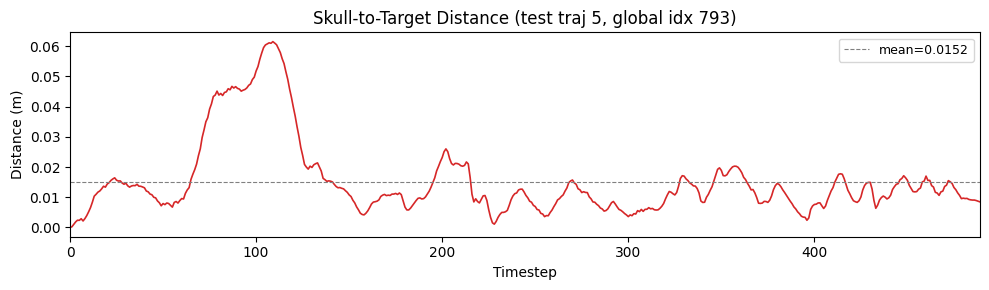

In [154]:
# Plot skull-to-moving-target distance over time
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(distances, color="tab:red", lw=1.2)
ax.set_xlabel("Timestep")
ax.set_ylabel("Distance (m)")
ax.set_title(
    f"Skull-to-Target Distance (test traj {TEST_TRAJ_IDX}, global idx {selected_traj_idx})"
)
ax.axhline(
    y=distances.mean(),
    color="gray",
    ls="--",
    lw=0.8,
    label=f"mean={distances.mean():.4f}",
)
ax.legend(fontsize=9)
ax.set_xlim(0, len(distances) - 1)
plt.tight_layout()
plt.show()

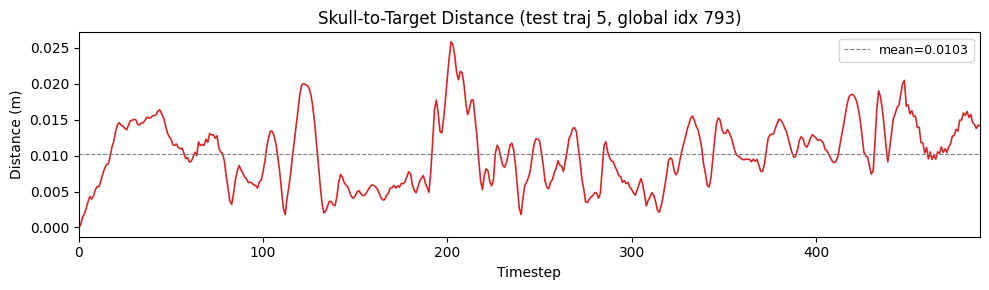

In [140]:
# Plot skull-to-moving-target distance over time
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(distances, color="tab:red", lw=1.2)
ax.set_xlabel("Timestep")
ax.set_ylabel("Distance (m)")
ax.set_title(
    f"Skull-to-Target Distance (test traj {TEST_TRAJ_IDX}, global idx {selected_traj_idx})"
)
ax.axhline(
    y=distances.mean(),
    color="gray",
    ls="--",
    lw=0.8,
    label=f"mean={distances.mean():.4f}",
)
ax.legend(fontsize=9)
ax.set_xlim(0, len(distances) - 1)
plt.tight_layout()
plt.show()

## Joint PCA — Encoder-Decoder (HDF5) vs Follow-Target

Fit PCA on joint angles from the encoder-decoder HDF5 trajectory and the
follow-target rollout. The encoder-decoder trajectory is coloured by time
(viridis) with the follow-target trajectory overlaid in orange.

In [155]:
# Extract follow_target joint angles (strip root qpos)
ft_joint_angles = qposes_ft[:, ROOT_QPOS_SIZE:]

# Combine all joint angles for a shared PCA
all_joints_combined = np.concatenate([enc_dec_joint_angles, ft_joint_angles], axis=0)

# Fit PCA
pca_combined = PCA(n_components=3)
pca_combined.fit(all_joints_combined)

explained = pca_combined.explained_variance_ratio_
print(f"Combined PCA (enc-dec HDF5 + follow_target)")
print(
    f"Explained variance: "
    f"PC1={explained[0]:.1%}, PC2={explained[1]:.1%}, PC3={explained[2]:.1%}"
)
print(f"Total: {sum(explained):.1%}")

# Project
projected_enc_dec = pca_combined.transform(enc_dec_joint_angles)
projected_ft = pca_combined.transform(ft_joint_angles)
print(f"\nEncoder-decoder (HDF5): {projected_enc_dec.shape}")
print(f"Follow-target rollout: {projected_ft.shape}")

Combined PCA (enc-dec HDF5 + follow_target)
Explained variance: PC1=37.6%, PC2=17.9%, PC3=8.8%
Total: 64.3%

Encoder-decoder (HDF5): (490, 3)
Follow-target rollout: (490, 3)


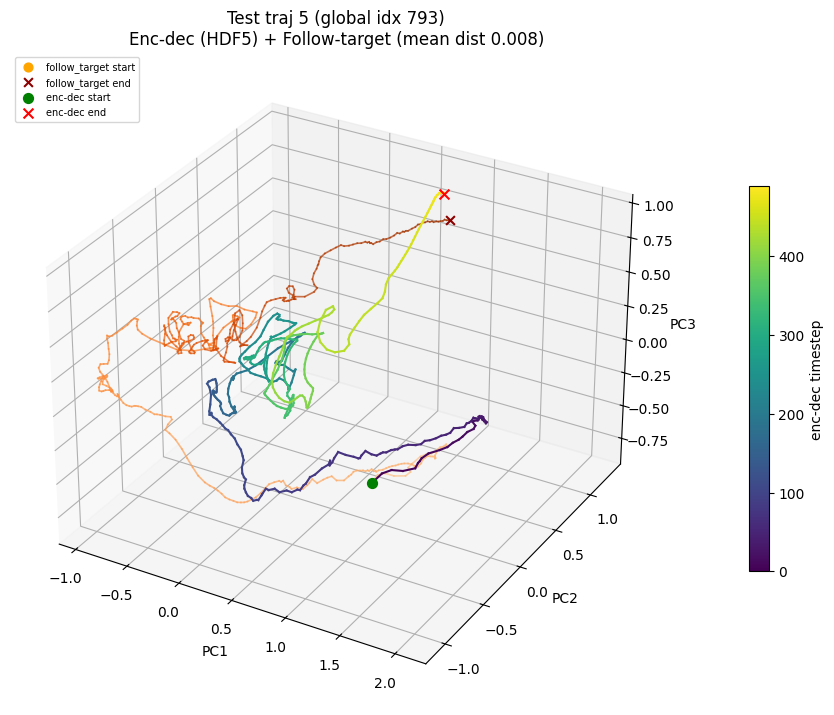

In [114]:
# Static 3D PCA plot
T_enc_dec = len(projected_enc_dec)
T_ft = len(projected_ft)

fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(111, projection="3d")

# --- Follow-target trajectory (orange, behind) ---
for t in range(T_ft - 1):
    frac = t / max(T_ft - 1, 1)
    ax.plot(
        projected_ft[t : t + 2, 0],
        projected_ft[t : t + 2, 1],
        projected_ft[t : t + 2, 2],
        color=plt.cm.Oranges(0.3 + 0.6 * frac),
        lw=1.2,
        alpha=0.7,
    )
ax.scatter(
    *projected_ft[0],
    s=40,
    c="orange",
    marker="o",
    zorder=4,
    label="follow_target start",
)
ax.scatter(
    *projected_ft[-1],
    s=40,
    c="darkred",
    marker="x",
    zorder=4,
    label="follow_target end",
)

# --- Encoder-decoder trajectory (viridis, on top) ---
for t in range(T_enc_dec - 1):
    frac = t / max(T_enc_dec - 1, 1)
    ax.plot(
        projected_enc_dec[t : t + 2, 0],
        projected_enc_dec[t : t + 2, 1],
        projected_enc_dec[t : t + 2, 2],
        color=plt.cm.viridis(frac),
        lw=1.5,
    )
ax.scatter(
    *projected_enc_dec[0], s=50, c="green", marker="o", zorder=5, label="enc-dec start"
)
ax.scatter(
    *projected_enc_dec[-1], s=50, c="red", marker="x", zorder=5, label="enc-dec end"
)

# Colorbar for encoder-decoder time
sm = plt.cm.ScalarMappable(cmap=plt.cm.viridis, norm=plt.Normalize(0, T_enc_dec - 1))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, shrink=0.5, pad=0.1)
cbar.set_label("enc-dec timestep")

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title(
    f"Test traj {TEST_TRAJ_IDX} (global idx {selected_traj_idx})\n"
    f"Enc-dec (HDF5) + Follow-target (mean dist {distances.mean():.3f})"
)
ax.legend(fontsize=7, loc="upper left")
plt.tight_layout()
plt.show()

In [156]:
# Interactive 3D PCA plot with plotly
fig = go.Figure()

# --- Follow-target trajectory (orange, colored by time) ---
fig.add_trace(
    go.Scatter3d(
        x=projected_ft[:, 0],
        y=projected_ft[:, 1],
        z=projected_ft[:, 2],
        mode="lines",
        line=dict(color=np.arange(T_ft), colorscale="Oranges", width=4),
        name="follow_target",
        hovertemplate="t=%{customdata}<br>PC1=%{x:.2f}<br>PC2=%{y:.2f}<br>PC3=%{z:.2f}",
        customdata=np.arange(T_ft),
    )
)
fig.add_trace(
    go.Scatter3d(
        x=[projected_ft[0, 0]],
        y=[projected_ft[0, 1]],
        z=[projected_ft[0, 2]],
        mode="markers",
        marker=dict(size=6, color="orange", symbol="circle"),
        name="follow_target start",
        showlegend=True,
    )
)
fig.add_trace(
    go.Scatter3d(
        x=[projected_ft[-1, 0]],
        y=[projected_ft[-1, 1]],
        z=[projected_ft[-1, 2]],
        mode="markers",
        marker=dict(size=6, color="darkred", symbol="x"),
        name="follow_target end",
        showlegend=True,
    )
)

# --- Encoder-decoder trajectory (viridis, colored by time) ---
fig.add_trace(
    go.Scatter3d(
        x=projected_enc_dec[:, 0],
        y=projected_enc_dec[:, 1],
        z=projected_enc_dec[:, 2],
        mode="lines",
        line=dict(
            color=np.arange(T_enc_dec),
            colorscale="Viridis",
            width=4,
            colorbar=dict(title="enc-dec step", x=1.02, len=0.5),
        ),
        name="enc-dec (HDF5)",
        hovertemplate="t=%{customdata}<br>PC1=%{x:.2f}<br>PC2=%{y:.2f}<br>PC3=%{z:.2f}",
        customdata=np.arange(T_enc_dec),
    )
)
fig.add_trace(
    go.Scatter3d(
        x=[projected_enc_dec[0, 0]],
        y=[projected_enc_dec[0, 1]],
        z=[projected_enc_dec[0, 2]],
        mode="markers",
        marker=dict(size=6, color="green", symbol="circle"),
        name="enc-dec start",
        showlegend=True,
    )
)
fig.add_trace(
    go.Scatter3d(
        x=[projected_enc_dec[-1, 0]],
        y=[projected_enc_dec[-1, 1]],
        z=[projected_enc_dec[-1, 2]],
        mode="markers",
        marker=dict(size=6, color="red", symbol="x"),
        name="enc-dec end",
        showlegend=True,
    )
)

fig.update_layout(
    title=dict(
        text=(
            f"Test traj {TEST_TRAJ_IDX} (global idx {selected_traj_idx})"
            f" \u2014 Enc-dec (HDF5) + Follow-target (mean dist {distances.mean():.3f})"
        ),
        font=dict(size=13),
    ),
    scene=dict(
        xaxis_title="PC1",
        yaxis_title="PC2",
        zaxis_title="PC3",
    ),
    width=850,
    height=700,
    legend=dict(x=0.01, y=0.99, font=dict(size=10)),
    margin=dict(l=0, r=0, t=60, b=0),
)
fig.show()

In [142]:
# Interactive 3D PCA plot with plotly
fig = go.Figure()

# --- Follow-target trajectory (orange, colored by time) ---
fig.add_trace(
    go.Scatter3d(
        x=projected_ft[:, 0],
        y=projected_ft[:, 1],
        z=projected_ft[:, 2],
        mode="lines",
        line=dict(color=np.arange(T_ft), colorscale="Oranges", width=4),
        name="follow_target",
        hovertemplate="t=%{customdata}<br>PC1=%{x:.2f}<br>PC2=%{y:.2f}<br>PC3=%{z:.2f}",
        customdata=np.arange(T_ft),
    )
)
fig.add_trace(
    go.Scatter3d(
        x=[projected_ft[0, 0]],
        y=[projected_ft[0, 1]],
        z=[projected_ft[0, 2]],
        mode="markers",
        marker=dict(size=6, color="orange", symbol="circle"),
        name="follow_target start",
        showlegend=True,
    )
)
fig.add_trace(
    go.Scatter3d(
        x=[projected_ft[-1, 0]],
        y=[projected_ft[-1, 1]],
        z=[projected_ft[-1, 2]],
        mode="markers",
        marker=dict(size=6, color="darkred", symbol="x"),
        name="follow_target end",
        showlegend=True,
    )
)

# --- Encoder-decoder trajectory (viridis, colored by time) ---
fig.add_trace(
    go.Scatter3d(
        x=projected_enc_dec[:, 0],
        y=projected_enc_dec[:, 1],
        z=projected_enc_dec[:, 2],
        mode="lines",
        line=dict(
            color=np.arange(T_enc_dec),
            colorscale="Viridis",
            width=4,
            colorbar=dict(title="enc-dec step", x=1.02, len=0.5),
        ),
        name="enc-dec (HDF5)",
        hovertemplate="t=%{customdata}<br>PC1=%{x:.2f}<br>PC2=%{y:.2f}<br>PC3=%{z:.2f}",
        customdata=np.arange(T_enc_dec),
    )
)
fig.add_trace(
    go.Scatter3d(
        x=[projected_enc_dec[0, 0]],
        y=[projected_enc_dec[0, 1]],
        z=[projected_enc_dec[0, 2]],
        mode="markers",
        marker=dict(size=6, color="green", symbol="circle"),
        name="enc-dec start",
        showlegend=True,
    )
)
fig.add_trace(
    go.Scatter3d(
        x=[projected_enc_dec[-1, 0]],
        y=[projected_enc_dec[-1, 1]],
        z=[projected_enc_dec[-1, 2]],
        mode="markers",
        marker=dict(size=6, color="red", symbol="x"),
        name="enc-dec end",
        showlegend=True,
    )
)

fig.update_layout(
    title=dict(
        text=(
            f"Test traj {TEST_TRAJ_IDX} (global idx {selected_traj_idx})"
            f" \u2014 Enc-dec (HDF5) + Follow-target (mean dist {distances.mean():.3f})"
        ),
        font=dict(size=13),
    ),
    scene=dict(
        xaxis_title="PC1",
        yaxis_title="PC2",
        zaxis_title="PC3",
    ),
    width=850,
    height=700,
    legend=dict(x=0.01, y=0.99, font=dict(size=10)),
    margin=dict(l=0, r=0, t=60, b=0),
)
fig.show()